# 🧠 ResNet50V2 — Multi-Class Brain Tumor Classification Using MRI
> **Published in IEEE ICONICA 2026** | **DOI**: [10.1109/ICONICA70605.2026.11736701](https://doi.org/10.1109/ICONICA70605.2026.11736701)


## 📦 1. Install & Import Libraries

In [1]:
import os
import shutil

# 1. Create a clean, flat folder in Kaggle's writable directory
FLAT_DATA_DIR = '/kaggle/working/clean_dataset'
os.makedirs(FLAT_DATA_DIR, exist_ok=True)

# 2. Map the unique Kaggle folder names to your clean class names
target_folders = {
    'Normal': 'normal',
    'glioma_tumor': 'glioma',
    'meningioma_tumor': 'meningioma',
    'pituitary_tumor': 'pituitary'
}

print("Hunting for the exact Kaggle folders...")

# 3. The "Search Dog" - scans everywhere inside /kaggle/input/
found_count = 0
for root, dirs, files in os.walk('/kaggle/input/'):
    for folder_name in dirs:
        if folder_name in target_folders:
            clean_name = target_folders[folder_name]
            weird_path = os.path.join(root, folder_name)
            dest_path  = os.path.join(FLAT_DATA_DIR, clean_name)
            
            # If we haven't copied it yet, do it now
            if not os.path.exists(dest_path):
                print(f"Found '{folder_name}' at -> {weird_path}")
                print(f"  Copying to -> {clean_name}...")
                shutil.copytree(weird_path, dest_path)
                found_count += 1

if found_count == 4:
    print("\nSuccess! Dataset is completely flattened and ready.")
else:
    print(f"\nUh oh, only found {found_count} out of 4 folders.")

Hunting for the exact Kaggle folders...

Uh oh, only found 0 out of 4 folders.


In [2]:
import os
import random
import shutil
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, regularizers
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.applications.resnet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, LearningRateScheduler

from sklearn.metrics import classification_report, confusion_matrix, roc_curve, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TF :', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU:', [g.name for g in gpus] if gpus else 'None (Using CPU)')

2026-05-14 02:24:14.174591: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778725454.198493     362 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778725454.206519     362 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778725454.226711     362 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778725454.226731     362 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778725454.226733     362 computation_placer.cc:177] computation placer alr

TF : 2.19.0
GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1']


## ⚙️ 2. Global Configuration

In [3]:
import os

# Ensure these local directories exist
for folder in ['models', 'outputs']:
    os.makedirs(folder, exist_ok=True)

# Point to the new flat folder we just created!
SOURCE_DATASET_PATH = '/kaggle/working/clean_dataset'   

# Classes are standard lowercase
CLASSES = ['glioma', 'meningioma', 'pituitary', 'normal']

# 2. Point the split output to Kaggle's writable working folder
SPLIT_DATA_DIR      = '/kaggle/working/split_data'         

MODEL_SAVE_PATH = '/kaggle/working/models/resnet50v2_multiclass.keras'

IMG_SIZE   = (300, 300)
BATCH_SIZE = 32

EPOCHS_P1     = 25
EPOCHS_P2     = 40
LR_P1         = 3e-3
LR_P2         = 1e-5
WEIGHT_DECAY  = 1e-4
LABEL_SMOOTH  = 0.10
UNFREEZE_LAST = 50
TTA_STEPS     = 8

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

print('Config loaded ✓')

Config loaded ✓


## 🔗 3. Mount Google Drive

In [4]:
# drive.mount('/content/drive')

# for cls in CLASSES:
#     p = os.path.join(DRIVE_DATASET_PATH, cls)
#     n = len([f for f in os.listdir(p) if f.lower().endswith(('.jpg','.jpeg','.png'))]) if os.path.isdir(p) else '⚠️ not found'
#     print(f'  {cls}: {n} images')

## ✂️ 4. Dataset Split (70 / 15 / 15)

In [5]:
def split_dataset(src_root, dst_root, classes, train_r=0.70, val_r=0.15, seed=42):
    rng = random.Random(seed)
    stats = {s: {} for s in ('train', 'val', 'test')}
    valid_exts = {'.jpg', '.jpeg', '.png', '.bmp', '.tiff'}

    for cls in classes:
        src_cls = os.path.join(src_root, cls)
        if not os.path.isdir(src_cls):
            raise FileNotFoundError(f"Missing directory: {src_cls}")
            
        imgs = sorted([f for f in os.listdir(src_cls) if os.path.splitext(f)[1].lower() in valid_exts])
        rng.shuffle(imgs)
        n_train = int(len(imgs) * train_r)
        n_val   = int(len(imgs) * val_r)
        splits  = {'train': imgs[:n_train], 'val': imgs[n_train: n_train + n_val], 'test': imgs[n_train + n_val:]}
        
        for split, lst in splits.items():
            dst = os.path.join(dst_root, split, cls)
            os.makedirs(dst, exist_ok=True)
            for f in lst:
                shutil.copy2(os.path.join(src_cls, f), os.path.join(dst, f))
            stats[split][cls] = len(lst)
    return stats

if os.path.isdir(SPLIT_DATA_DIR):
    print(f'Split directory {SPLIT_DATA_DIR} already exists — skipping copy.')
else:
    print('Splitting dataset locally...')
    stats = split_dataset(SOURCE_DATASET_PATH, SPLIT_DATA_DIR, CLASSES, TRAIN_RATIO, VAL_RATIO, SEED)
    print('Done ✓')

Split directory /kaggle/working/split_data already exists — skipping copy.


## 🔄 5. Data Generators — Richer Augmentation

In [6]:
train_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    rotation_range         = 15,
    zoom_range             = 0.10,
    width_shift_range      = 0.10,
    height_shift_range     = 0.10,
    horizontal_flip        = True,
    vertical_flip          = True,
    brightness_range       = [0.90, 1.10],
    fill_mode              = 'constant',
    cval                   = 0
)

val_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

flow_kw = dict(target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASSES, seed=SEED)
train_gen = train_datagen.flow_from_directory(os.path.join(SPLIT_DATA_DIR, 'train'), shuffle=True, **flow_kw)
val_gen   = val_test_datagen.flow_from_directory(os.path.join(SPLIT_DATA_DIR, 'val'), shuffle=False, **flow_kw)
test_gen  = val_test_datagen.flow_from_directory(os.path.join(SPLIT_DATA_DIR, 'test'), shuffle=False, **flow_kw)

labels_all = train_gen.classes
cw_vals    = compute_class_weight('balanced', classes=np.unique(labels_all), y=labels_all)
CLASS_WEIGHT = dict(enumerate(cw_vals))

Found 11099 images belonging to 4 classes.
Found 2375 images belonging to 4 classes.
Found 2383 images belonging to 4 classes.


## 🖼️ 6. Sample Augmented Images

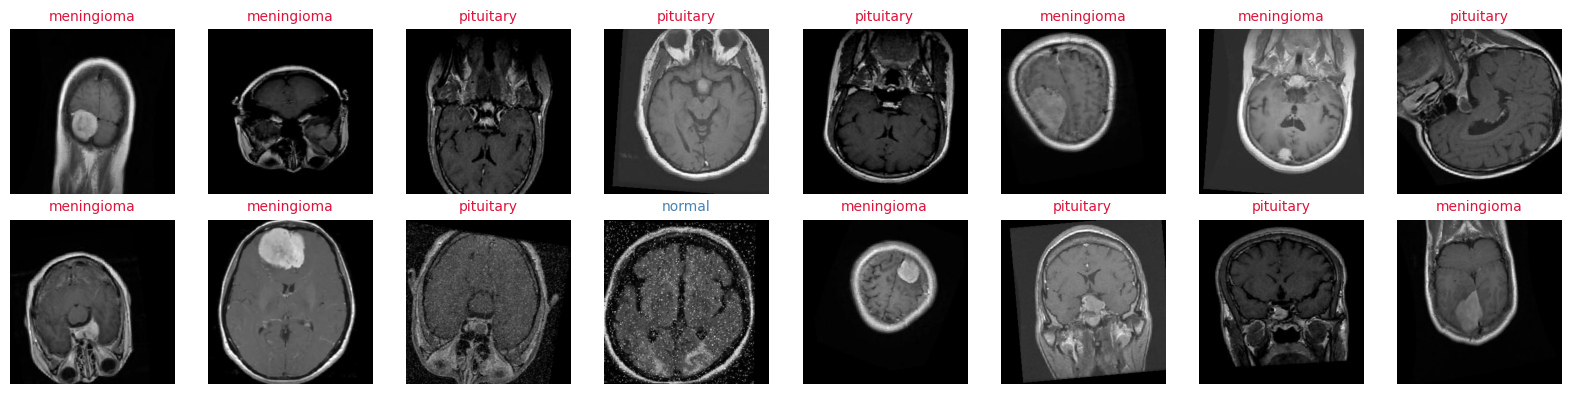

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def show_sample_images(gen, n_cols=8, n_rows=2):
    imgs, labels = next(gen)
    id2cls = {v: k for k, v in gen.class_indices.items()}
   
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*2, n_rows*2))
    for i, ax in enumerate(axes.flatten()):
        if i < len(imgs):
           
            # 🔥 THE FIX: De-process DenseNet's negative values for the human eye
            img = imgs[i]
            img_display = img - img.min()  # Shift the lowest negative value up to 0.0
            if img_display.max() > 0:
                img_display = img_display / img_display.max()  # Scale the highest value to 1.0
               
            # Plot the brightly normalized image
            ax.imshow(img_display)
           
            # Convert one-hot array [0,1,0,0] into an integer index
            class_idx = int(np.argmax(labels[i]))
            class_name = id2cls[class_idx]
           
            # Color logic: blue for normal, red for the 3 tumor types
            text_color = 'steelblue' if class_name == 'normal' else 'crimson'
           
            ax.set_title(class_name, fontsize=10, color=text_color)
           
        ax.axis('off')
   
    plt.tight_layout()
    plt.show()

# Now call it!
show_sample_images(train_gen)


## 🏗️ 7. Model Architecture — B3 + Dual Pooling + L2 Regularisation

In [8]:
def build_model(input_shape=(*IMG_SIZE, 3)):
    backbone = ResNet50V2(include_top=False, weights='imagenet', input_shape=input_shape)
    backbone.trainable = False

    inputs = keras.Input(shape=input_shape, name='input_image')
    x      = backbone(inputs, training=False)

    avg = layers.GlobalAveragePooling2D(name='gap')(x)
    mx  = layers.GlobalMaxPooling2D(name='gmp')(x)
    x   = layers.Concatenate(name='dual_pool')([avg, mx])
    x   = layers.BatchNormalization(name='bn_pool')(x)

    x = layers.Dense(512, activation='relu', name='dense_512')(x)
    x = layers.Dropout(0.3, seed=SEED, name='drop_03')(x)
    x = layers.Dense(128, activation='relu', name='dense_128')(x)
    x = layers.Dropout(0.2, seed=SEED, name='drop_02')(x)
    outputs = layers.Dense(4, activation='softmax', name='output')(x)

    return Model(inputs, outputs, name='BrainTumorV2'), backbone

model, backbone = build_model()

I0000 00:00:1778725464.990983     362 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1778725464.996189     362 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## 📐 8. Cosine-Decay LR Schedule Helper

In [9]:
def cosine_decay_schedule(initial_lr, total_epochs, warmup_epochs=3, min_lr=1e-8):
    def schedule(epoch, lr):
        if epoch < warmup_epochs: return float(initial_lr * (epoch + 1) / warmup_epochs)
        progress = (epoch - warmup_epochs) / max(total_epochs - warmup_epochs, 1)
        return float(max(min_lr, min_lr + (initial_lr - min_lr) * 0.5 * (1 + np.cos(np.pi * progress))))
    return LearningRateScheduler(schedule, verbose=0)

## 🔵 9. Phase 1 Training — Frozen Backbone

In [10]:
model.compile(
    optimizer = tf.keras.optimizers.AdamW(learning_rate=LR_P1, weight_decay=WEIGHT_DECAY),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy', keras.metrics.AUC(name='auc'), keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]
)

callbacks_p1 = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ModelCheckpoint('./models/best_p1.keras', monitor='val_auc', save_best_only=True, verbose=1),
    cosine_decay_schedule(LR_P1, EPOCHS_P1, warmup_epochs=3),
]

print('━' * 60)
print('PHASE 1 — Frozen backbone')
print('━' * 60)
history_p1 = model.fit(train_gen, epochs=EPOCHS_P1, validation_data=val_gen, class_weight=CLASS_WEIGHT, callbacks=callbacks_p1, verbose=1)
p1_epochs_run = len(history_p1.history['loss'])
print(f'Phase 1 done: {p1_epochs_run} epochs.')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
PHASE 1 — Frozen backbone
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Epoch 1/25


I0000 00:00:1778725475.801301     453 service.cc:152] XLA service 0x7d1cc4014000 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778725475.801339     453 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1778725475.801343     453 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1778725477.514357     453 cuda_dnn.cc:529] Loaded cuDNN version 91002


  1/347 ━━━━━━━━━━━━━━━━━━━━ 2:01:30 21s/step - accuracy: 0.3750 - auc: 0.5724 - loss: 1.8985 - precision: 0.4762 - recall: 0.3125

I0000 00:00:1778725489.206152     453 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


347/347 ━━━━━━━━━━━━━━━━━━━━ 0s 712ms/step - accuracy: 0.6780 - auc: 0.8795 - loss: 1.1058 - precision: 0.7019 - recall: 0.6582
Epoch 1: val_auc improved from inf to 0.94830, saving model to ./models/best_p1.keras
347/347 ━━━━━━━━━━━━━━━━━━━━ 289s 773ms/step - accuracy: 0.6782 - auc: 0.8796 - loss: 1.1051 - precision: 0.7020 - recall: 0.6583 - val_accuracy: 0.7836 - val_auc: 0.9483 - val_loss: 0.5504 - val_precision: 0.8237 - val_recall: 0.7280 - learning_rate: 0.0010
Epoch 2/25
347/347 ━━━━━━━━━━━━━━━━━━━━ 0s 681ms/step - accuracy: 0.7621 - auc: 0.9334 - loss: 0.6492 - precision: 0.7848 - recall: 0.7281
Epoch 2: val_auc did not improve from 0.94830
347/347 ━━━━━━━━━━━━━━━━━━━━ 248s 713ms/step - accuracy: 0.7621 - auc: 0.9334 - loss: 0.6492 - precision: 0.7849 - recall: 0.7281 - val_accuracy: 0.8337 - val_auc: 0.9649 - val_loss: 0.4457 - val_precision: 0.8626 - val_recall: 0.8038 - learning_rate: 0.0020
Epoch 3/25
347/347 ━━━━━━━━━━━━━━━━━━━━ 0s 686ms/step - accuracy: 0.8017 - auc: 0.9

## 🔴 10. Phase 2 Training — Unfreeze Last 50 Layers

In [11]:
backbone.trainable = True
for layer in backbone.layers[:-UNFREEZE_LAST]: layer.trainable = False
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization): layer.trainable = False

model.compile(
    optimizer = tf.keras.optimizers.AdamW(learning_rate=LR_P2, weight_decay=WEIGHT_DECAY/10),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy', keras.metrics.AUC(name='auc'), keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]
)

callbacks_p2 = [
    EarlyStopping(monitor='val_auc', patience=12, restore_best_weights=True, verbose=1, mode='max'),
    ModelCheckpoint('./models/best_p2.keras', monitor='val_auc', save_best_only=True, verbose=1, mode='max'),
    cosine_decay_schedule(LR_P2, EPOCHS_P2, warmup_epochs=2),
]

print('━' * 60)
print(f'PHASE 2 — Fine-tune last {UNFREEZE_LAST} layers')
print('━' * 60)
history_p2 = model.fit(train_gen, epochs=EPOCHS_P2, validation_data=val_gen, class_weight=CLASS_WEIGHT, callbacks=callbacks_p2, verbose=1)
p2_epochs_run = len(history_p2.history['loss'])
print(f'Phase 2 done: {p2_epochs_run} epochs.')

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
PHASE 2 — Fine-tune last 50 layers
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Epoch 1/40
347/347 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - accuracy: 0.9545 - auc: 0.9953 - loss: 0.1274 - precision: 0.9598 - recall: 0.9477
Epoch 1: val_auc improved from -inf to 0.99636, saving model to ./models/best_p2.keras
347/347 ━━━━━━━━━━━━━━━━━━━━ 290s 775ms/step - accuracy: 0.9545 - auc: 0.9953 - loss: 0.1274 - precision: 0.9598 - recall: 0.9477 - val_accuracy: 0.9655 - val_auc: 0.9964 - val_loss: 0.1160 - val_precision: 0.9670 - val_recall: 0.9638 - learning_rate: 5.0000e-06
Epoch 2/40
347/347 ━━━━━━━━━━━━━━━━━━━━ 0s 676ms/step - accuracy: 0.9599 - auc: 0.9961 - loss: 0.1127 - precision: 0.9639 - recall: 0.9537
Epoch 2: val_auc did not improve from 0.99636
347/347 ━━━━━━━━━━━━━━━━━━━━ 246s 707ms/step - accuracy: 0.9599 - auc: 0.9961 - loss: 0.1128 - precision: 0.9639 - recall: 0.9537 - val_accuracy: 0.9697 - val_auc: 0.995

## 📈 11. Merged Training Curves

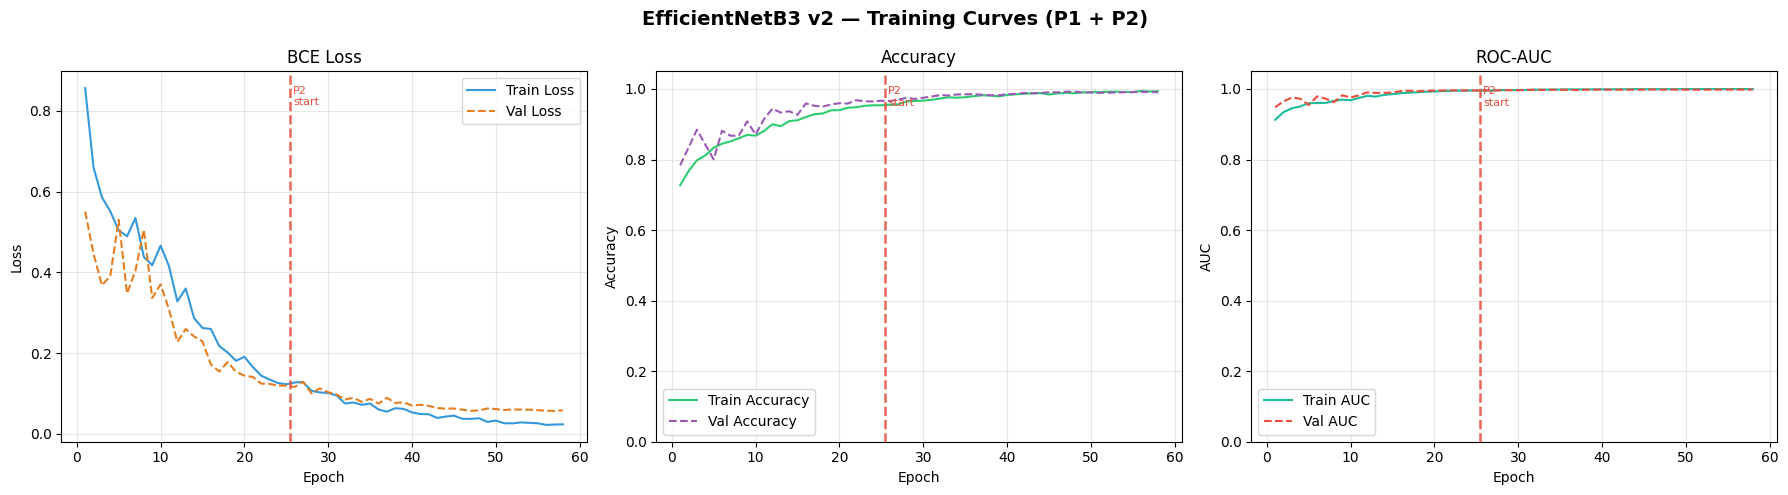

Saved → ./outputs/training_curves.png


In [12]:
def merge_histories(h1, h2):
    return {k: h1[k] + h2.get(k, []) for k in h1}


def plot_training_curves(history, phase_boundary,
                          save_path='./outputs/training_curves.png'):
    epochs  = range(1, len(history['loss']) + 1)
    pb      = phase_boundary
    bkw     = dict(x=pb+0.5, color='#e74c3c', lw=1.8, ls='--', alpha=0.85)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('EfficientNetB3 v2 — Training Curves (P1 + P2)',
                 fontsize=14, fontweight='bold')

    def _vline(ax):
        ax.axvline(**bkw)
        ax.text(pb+0.8, ax.get_ylim()[1]*0.96,
                'P2\nstart', color='#e74c3c', fontsize=8, va='top')

    specs = [
        ('loss',     'val_loss',     'Loss',     'BCE Loss',  '#3498db', '#e67e22'),
        ('accuracy', 'val_accuracy', 'Accuracy', 'Accuracy',  '#2ecc71', '#9b59b6'),
        ('auc',      'val_auc',      'AUC',      'ROC-AUC',   '#1abc9c', '#e74c3c'),
    ]
    for ax, (tr_key, va_key, ylabel, title, c1, c2) in zip(axes, specs):
        ax.plot(epochs, history[tr_key], label=f'Train {ylabel}', color=c1)
        ax.plot(epochs, history[va_key], label=f'Val {ylabel}',
                color=c2, linestyle='--')
        ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel)
        ax.legend(); ax.grid(True, alpha=0.3)
        if ylabel in ('Accuracy', 'AUC'):
            ax.set_ylim([0, 1.05])
        _vline(ax)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved → {save_path}')


merged = merge_histories(history_p1.history, history_p2.history)
plot_training_curves(merged, p1_epochs_run)

## 🧪 12. Test-Time Augmentation (TTA ×8)

In [13]:
## 🧪 12. Standard Evaluation
from sklearn.metrics import accuracy_score
import numpy as np

print('── Standard Evaluation ──')
test_gen.reset()
y_true_test = test_gen.classes

# CRITICAL: Removed .ravel() so the shape stays (N, 4)
y_prob_test = model.predict(test_gen, verbose=0)

# Multi-Class Logic: The prediction is simply the class with the highest probability
y_pred_test = np.argmax(y_prob_test, axis=1)

print(f"Standard Multi-Class Accuracy: {accuracy_score(y_true_test, y_pred_test):.4f}")

── Standard Evaluation ──
Standard Multi-Class Accuracy: 0.9895


In [14]:
print(f'\n── Running TTA ({TTA_STEPS} passes) ──')

# Use the upgraded medical imaging augmentation (constant black padding)
tta_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input, 
    rotation_range         = 15,
    zoom_range             = 0.10,
    horizontal_flip        = True,
    vertical_flip          = True,
    fill_mode              = 'constant',
    cval                   = 0
)

def predict_with_tta(model, data_dir, img_size, batch_size, classes, tta_steps=8, seed=42):
    """Runs forward passes with random augmentation and averages probabilities."""
    
    # CRITICAL FIX: Changed class_mode to 'categorical'
    flow_kw = dict(target_size=img_size, batch_size=batch_size, 
                   class_mode='categorical', classes=classes, shuffle=False)
    
    probs_all = []
    for i in range(tta_steps):
        # Change seed slightly for each pass to get different augmentations
        gen = tta_datagen.flow_from_directory(data_dir, **{**flow_kw, 'seed': seed + i})
        
        # CRITICAL FIX: Removed .ravel()
        p = model.predict(gen, verbose=0)
        probs_all.append(p)
        print(f'  TTA pass {i+1}/{tta_steps} completed.')
        
    # Average the (N, 4) probability matrices across all 8 passes
    return np.mean(probs_all, axis=0)

# Run TTA exactly once
y_prob_tta = predict_with_tta(
    model,
    data_dir   = os.path.join(SPLIT_DATA_DIR, 'test'),
    img_size   = IMG_SIZE,
    batch_size = BATCH_SIZE,
    classes    = CLASSES,
    tta_steps  = TTA_STEPS,
    seed       = SEED,
)

# Apply standard multi-class logic (pick highest probability)
y_pred_tta = np.argmax(y_prob_tta, axis=1)
tta_acc = accuracy_score(y_true_test, y_pred_tta)

print(f'\nMulti-Class TTA Accuracy: {tta_acc:.4f}')


── Running TTA (8 passes) ──
Found 2383 images belonging to 4 classes.
  TTA pass 1/8 completed.
Found 2383 images belonging to 4 classes.
  TTA pass 2/8 completed.
Found 2383 images belonging to 4 classes.
  TTA pass 3/8 completed.
Found 2383 images belonging to 4 classes.
  TTA pass 4/8 completed.
Found 2383 images belonging to 4 classes.
  TTA pass 5/8 completed.
Found 2383 images belonging to 4 classes.
  TTA pass 6/8 completed.
Found 2383 images belonging to 4 classes.
  TTA pass 7/8 completed.
Found 2383 images belonging to 4 classes.
  TTA pass 8/8 completed.

Multi-Class TTA Accuracy: 0.9945


## 🗺️ 14. Confusion Matrix (TTA Predictions)

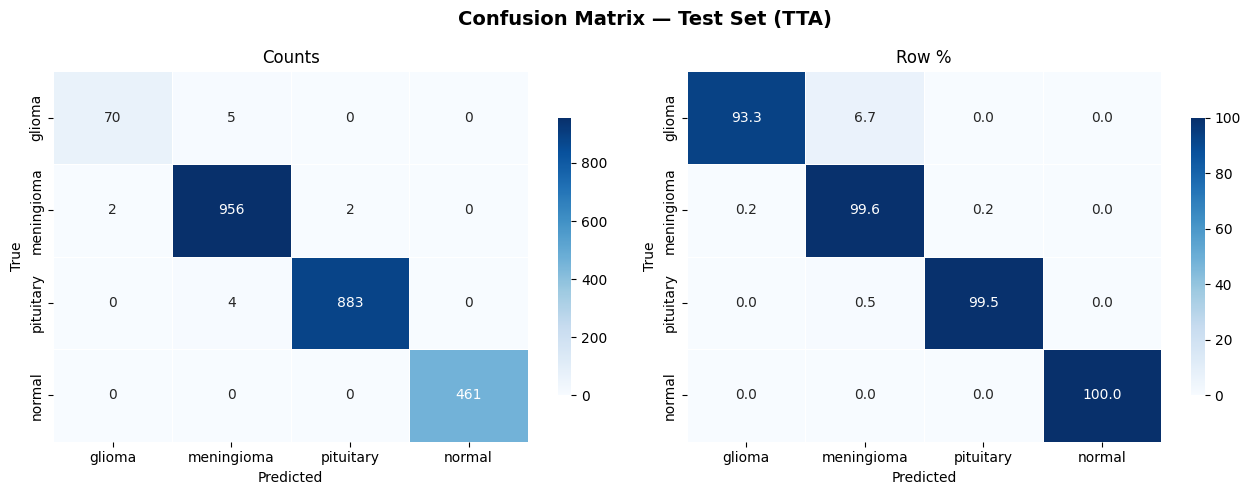

In [15]:
def plot_confusion_matrix(y_true, y_pred, class_names,
                          save_path='./outputs/confusion_matrix.png', title_suffix=''):
    cm     = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(f'Confusion Matrix — Test Set {title_suffix}',
                 fontsize=14, fontweight='bold')

    for ax, data, fmt, title in zip(
        axes, [cm, cm_pct], ['d', '.1f'], ['Counts', 'Row %']
    ):
        sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues',
                    xticklabels=class_names, yticklabels=class_names,
                    linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.75})
        ax.set_title(title, fontsize=12)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


label_names = [k for k, _ in sorted(
    train_gen.class_indices.items(), key=lambda x: x[1])]
plot_confusion_matrix(y_true_test, y_pred_tta, label_names,
                      title_suffix='(TTA)')

## 📋 15. Classification Report

In [16]:
report = classification_report(y_true_test, y_pred_tta,
                                target_names=label_names, digits=4)
print('Classification Report (TTA)')
print('=' * 60)
print(report)

with open('./outputs/classification_report.txt', 'w') as f:
    f.write('Classification Report (TTA)\n' + '='*60 + '\n' + report)
print('Saved → ./outputs/classification_report.txt')

Classification Report (TTA)
              precision    recall  f1-score   support

      glioma     0.9722    0.9333    0.9524        75
  meningioma     0.9907    0.9958    0.9932       960
   pituitary     0.9977    0.9955    0.9966       887
      normal     1.0000    1.0000    1.0000       461

    accuracy                         0.9945      2383
   macro avg     0.9902    0.9812    0.9856      2383
weighted avg     0.9945    0.9945    0.9945      2383

Saved → ./outputs/classification_report.txt


## 🔥 16. Grad-CAM Visualisation

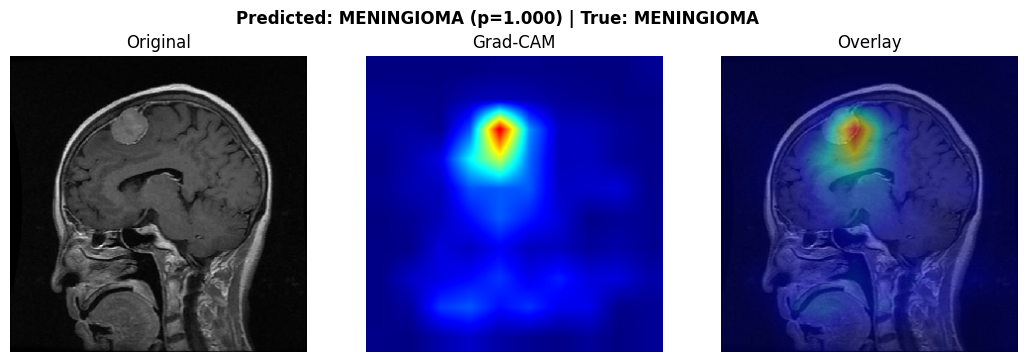

In [17]:
## 🔥 16. Grad-CAM Visualisation (Multi-Class & Multi-Model)

import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array

def make_gradcam_heatmap(img_array, model, pred_index=None):
    # DYNAMIC BACKBONE FIX: Works instantly for EfficientNet, DenseNet, AND ResNet!
    backbone = model.layers[1]
    
    l_gap, l_gmp, l_concat, l_bn = model.get_layer('gap'), model.get_layer('gmp'), model.get_layer('dual_pool'), model.get_layer('bn_pool')
    l_d1, l_drop1, l_d2, l_drop2, l_out = model.layers[-5:]

    with tf.GradientTape() as tape:
        conv_outputs = backbone(img_array, training=False)
        tape.watch(conv_outputs)
        
        x = l_bn(l_concat([l_gap(conv_outputs), l_gmp(conv_outputs)]), training=False)
        x = l_drop2(l_d2(l_drop1(l_d1(x), training=False)), training=False)
        predictions = l_out(x)
        
        # MULTI-CLASS FIX: Dynamically watch the highest probability class
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    return (tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-9)).numpy()


def overlay_gradcam(img_path, model, class_names=CLASSES, save_path='./outputs/gradcam.png'):
    img = load_img(img_path, target_size=IMG_SIZE)
    raw_arr = img_to_array(img)
    img_batch = np.expand_dims(preprocess_input(raw_arr.copy()), 0)

    # MULTI-CLASS FIX: Grab all 4 probabilities, find the highest one, and get its name
    preds = model.predict(img_batch, verbose=0)[0]
    pred_idx = int(np.argmax(preds))
    pred_class = class_names[pred_idx]
    pred_prob = preds[pred_idx]

    heatmap = make_gradcam_heatmap(img_batch, model, pred_index=pred_idx)
    
    heatmap_resized = cv2.resize(heatmap, (IMG_SIZE[1], IMG_SIZE[0]))
    jet_heatmap = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB) / 255.0

    orig_norm = raw_arr / 255.0
    overlay = np.clip(0.45 * jet_heatmap + 0.55 * orig_norm, 0, 1)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, im, t in zip(axes, [orig_norm, jet_heatmap, overlay], ['Original', 'Grad-CAM', 'Overlay']):
        ax.imshow(im); ax.set_title(t); ax.axis('off')

    # Shows the exact prediction, probability, AND the true class from the folder name
    true_folder = os.path.basename(os.path.dirname(img_path))
    plt.suptitle(f"Predicted: {pred_class.upper()} (p={pred_prob:.3f}) | True: {true_folder.upper()}", fontweight='bold')
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()


# ── Run the visualizer ────────────────────────────────────────────────────────
import random

test_cls = random.choice(CLASSES)
test_dir = os.path.join(SPLIT_DATA_DIR, 'test', test_cls)
sample_img = os.path.join(test_dir, random.choice(os.listdir(test_dir)))

# Just drop in the image and the model. No thresholds!
overlay_gradcam(sample_img, model)

## 🔍 17. Single-Image Inference with Confidence Bar

Random image: /kaggle/working/split_data/test/pituitary/P_212.jpg


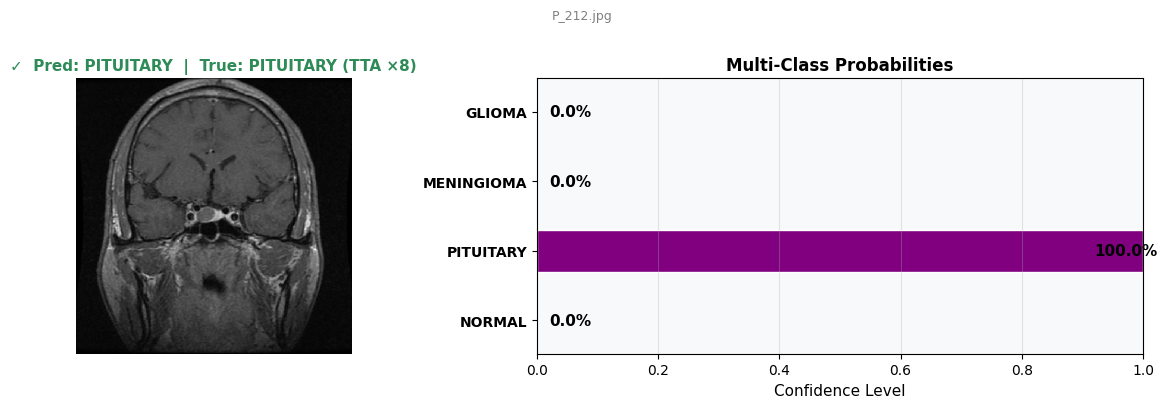

In [18]:
## 🔍 17. Single-Image Inference with Confidence Bar (Multi-Class)

import os
import random
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# 1. Removed 'threshold' from parameters entirely!
def predict_image(img_path=None, use_tta=True, tta_n=TTA_STEPS):
    """
    Single-image inference with optional TTA.
    If img_path is None, picks a random test image.
    """
    # Ensure classes match standard formatting
    class_names = [c.lower() for c in CLASSES]
    true_label = None

    if img_path is None:
        rng        = random.Random()
        cls_name   = rng.choice(CLASSES)
        cls_dir    = os.path.join(SPLIT_DATA_DIR, 'test', cls_name)
        img_path   = os.path.join(cls_dir, rng.choice(os.listdir(cls_dir)))
        true_label = cls_name.lower()
        print(f'Random image: {img_path}')

    img       = load_img(img_path, target_size=IMG_SIZE)
    raw       = img_to_array(img)
    proc      = preprocess_input(raw.copy())
    img_batch = np.expand_dims(proc, 0)

    if use_tta:
        tta_aug = ImageDataGenerator(
            preprocessing_function = None, 
            horizontal_flip=True, vertical_flip=True,
            rotation_range=10, fill_mode='constant', cval=0
        )
        probs = []
        for _ in range(tta_n):
            aug_batch = next(tta_aug.flow(img_batch, batch_size=1, shuffle=False))
            # MULTI-CLASS FIX: Grab all 4 probabilities, not just [0][0]
            probs.append(model.predict(aug_batch, verbose=0)[0])
            
        # Average the arrays across all TTA passes
        prob_array = np.mean(probs, axis=0)
    else:
        prob_array = model.predict(img_batch, verbose=0)[0]

    # 2. MULTI-CLASS FIX: Find the highest probability instead of using a threshold
    pred_idx = int(np.argmax(prob_array))
    pred_label = class_names[pred_idx]
    confidence = prob_array[pred_idx]

    # 3. Dynamic Plotting
    fig, (ax_img, ax_bar) = plt.subplots(
        1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1.4]}
    )
    
    # --- Image Subplot ---
    ax_img.imshow(raw / 255.0)
    txt = f'Prediction: {pred_label.upper()}'
    tc = 'steelblue' # default color
    
    if true_label:
        mark = '✓' if pred_label == true_label else '✗'
        tc = 'seagreen' if pred_label == true_label else 'crimson'
        txt  = f'{mark}  Pred: {pred_label.upper()}  |  True: {true_label.upper()}'
        
    tta_note = f' (TTA ×{tta_n})' if use_tta else ''
    ax_img.set_title(txt + tta_note, fontsize=11, fontweight='bold', color=tc)
    ax_img.axis('off')

    # --- Confidence Bar Subplot ---
    # Colors for: Glioma, Meningioma, Pituitary, Normal
    bar_colors = ['crimson', 'darkorange', 'purple', 'steelblue'] 
    y_pos = np.arange(len(class_names))
    
    # Draw 4 separate bars
    bars = ax_bar.barh(y_pos, prob_array, color=bar_colors, height=0.6, edgecolor='white')
    
    ax_bar.set_yticks(y_pos)
    ax_bar.set_yticklabels([c.upper() for c in class_names], fontsize=10, fontweight='bold')
    ax_bar.invert_yaxis()  # Highest index at the bottom
    
    ax_bar.set_xlim(0, 1)
    ax_bar.set_xlabel('Confidence Level', fontsize=11)
    ax_bar.set_title('Multi-Class Probabilities', fontsize=12, fontweight='bold')
    ax_bar.grid(True, axis='x', alpha=0.3)
    ax_bar.set_facecolor('#f8f9fa')
    
    # Apply percentage text to all 4 bars
    for bar, p in zip(bars, prob_array):
        ax_bar.text(min(p + 0.02, 0.92), bar.get_y() + bar.get_height()/2,
                    f'{p*100:.1f}%', va='center', fontsize=11, fontweight='bold')

    fig.suptitle(Path(img_path).name, fontsize=9, color='grey', y=1.01)
    plt.tight_layout()
    plt.savefig('./outputs/inference_result.png', dpi=150, bbox_inches='tight')
    plt.show()

    result = dict(
        path=img_path, 
        true_label=true_label, 
        pred_label=pred_label,
        confidence=round(float(confidence), 4)
    )
    return result


# 4. Run it without the threshold!
result = predict_image()

## 💾 18. Save Final Multi-Class Model

In [19]:
## 💾 18. Save Final Multi-Class Model

# Save the trained model weights and architecture
model.save(MODEL_SAVE_PATH)

print(f'\n🎉 Finished! Multi-Class Model successfully saved to: {MODEL_SAVE_PATH}')
print('Ready for download and Macro-ROC evaluation!')


🎉 Finished! Multi-Class Model successfully saved to: /kaggle/working/models/resnet50v2_multiclass.keras
Ready for download and Macro-ROC evaluation!


In [20]:
import os
import json
import numpy as np
from sklearn.metrics import classification_report

# Ensure output directory exists
os.makedirs('./outputs', exist_ok=True)

print('── Initiating Master Save Sequence ──')

# 1. Save the Heavy Model Weights (Just in case you need to deploy it later)
model.save(MODEL_SAVE_PATH)
print(f"✅ 1. Model architecture and weights saved to: {MODEL_SAVE_PATH}")

# 2. Save the Raw Test Arrays (The secret to fast Macro-ROC plotting)
# If you didn't run TTA in a specific notebook, change 'y_prob_tta' to 'y_prob_test'
np.savez('./outputs/efficientnet_metrics.npz', 
         y_true=y_true_test, 
         y_prob=y_prob_tta) 
print(f"✅ 2. Raw test metrics saved to: ./outputs/efficientnet_metrics.npz")

# 3. Save the Classification Report as a JSON (For easy comparison tables later)
y_pred_final = np.argmax(y_prob_tta, axis=1)
report_dict = classification_report(y_true_test, y_pred_final, target_names=CLASSES, output_dict=True)

with open('./outputs/resnet50v2_report.json', 'w') as f:
    json.dump(report_dict, f, indent=4)
print(f"✅ 3. Classification report saved to: ./outputs/resnet50v2_report.json")

print('\n🎉 All artifacts saved successfully! Ready for download.')

── Initiating Master Save Sequence ──
✅ 1. Model architecture and weights saved to: /kaggle/working/models/resnet50v2_multiclass.keras
✅ 2. Raw test metrics saved to: ./outputs/efficientnet_metrics.npz
✅ 3. Classification report saved to: ./outputs/resnet50v2_report.json

🎉 All artifacts saved successfully! Ready for download.


In [21]:
import os
import shutil
from IPython.display import FileLink

# Ensure we are in the correct directory
os.chdir(r'/kaggle/working')

print("Zipping all models and outputs. This might take a minute...")

# Create a zip file named 'full_project_backup.zip' containing everything
shutil.make_archive('full_project_backup', 'zip', '/kaggle/working')

print("Done! Click the link below to download:")

# Generate the clickable download link
FileLink(r'full_project_backup.zip')

Zipping all models and outputs. This might take a minute...
Done! Click the link below to download:


/kaggle/working/full_project_backup.zip

## Verify

In [22]:
loaded = keras.models.load_model(MODEL_SAVE_PATH)
test_gen.reset()
loaded.evaluate(test_gen, verbose=1)

75/75 ━━━━━━━━━━━━━━━━━━━━ 19s 174ms/step - accuracy: 0.9822 - auc: 0.9970 - loss: 0.0720 - precision: 0.9822 - recall: 0.9811


[0.03353116288781166,
 0.9895090460777283,
 0.9992784261703491,
 0.9895002245903015,
 0.988669753074646]